Modelo Desing Thinking - Rechazo de botellas - 0.2% -

In [9]:
# INSTALACIÓN DE LIBRERÍAS
!pip install mlflow -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    precision_recall_curve, auc, confusion_matrix
)
import mlflow
import mlflow.sklearn

# Configuración estilos visuales
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [10]:
# CARGA Y LIMPIEZA / ESTANDARIZACIÓN DE DATOS

file_name = 'dataset_inspeccion_0_2 rechazo.csv'
df = pd.read_csv(file_name)

print(f"Dimensiones originales del dataset: {df.shape}")

# Proceso de limpieza y estandarización:
# - Eliminar duplicados si los hubiera
df = df.drop_duplicates()

# - Manejo de valores nulos (si existieran, imputar o eliminar)
df = df.dropna()

# Estandarización de variables categóricas
df['label_present_num'] = df['label_present'].str.strip().str.upper().map({'SI': 1, 'NO': 0})

# Codificación de la variable objetivo (0 = Aceptado, 1 = Rechazado/Defecto)
df['target'] = df['status'].str.strip().str.upper().map({'ACEPTADO': 0, 'RECHAZADO': 1})

# Estandarización de variables numéricas (Escalamiento de la característica de nivel de llenado)
scaler = StandardScaler()
df['fill_level_scaled'] = scaler.fit_transform(df[['fill_level_ml']])

print(f"Dimensiones tras la limpieza: {df.shape}")
print("Distribución de clases (Target):\n", df['target'].value_counts(normalize=True))

# Definir características (X) y objetivo (y)
X = df[['fill_level_scaled', 'label_present_num']]
y = df['target']

Dimensiones originales del dataset: (5000, 4)
Dimensiones tras la limpieza: (5000, 7)
Distribución de clases (Target):
 target
0    0.998
1    0.002
Name: proportion, dtype: float64


In [11]:
# 2 CONFIGURACIÓN EN MLFLOW

mlflow.set_experiment("Inspeccion_Calidad_Botellas_0.5pct")

# Validación cruzada estratificada (necesaria por el alto desbalance de clases)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [12]:
# 3 DEFINICIÓN DE MODELOS E HIPERPARÁMETROS (Grid Search)

modelos_config = {
    "LogisticRegression": {
        "model": LogisticRegression(random_state=42),
        "params": {
            'C': [0.01, 0.1, 1.0, 10.0],
            'class_weight': ['balanced']
        }
    },
    "RandomForest": {
        "model": RandomForestClassifier(random_state=42),
        "params": {
            'n_estimators': [50, 100],
            'max_depth': [3, 5, 10],
            'class_weight': ['balanced', 'balanced_subsample']
        }
    }
}

resultados_metricas = []

In [13]:
# 4 ENTRENAMIENTO, VALIDACIÓN Y LOGGING EN MLFLOW

for nombre_modelo, config in modelos_config.items():
    print(f"\n--- Optimizando y Evaluando: {nombre_modelo} ---")

    # Grid Search con F1-Score como métrica de optimización para clases desbalanceadas
    grid_search = GridSearchCV(
        estimator=config["model"],
        param_grid=config["params"],
        scoring='f1',
        cv=skf,
        n_jobs=-1
    )

    grid_search.fit(X, y)
    mejor_modelo = grid_search.best_estimator_

    with mlflow.start_run(run_name=f"{nombre_modelo}_Optimizado"):
        # Registrar hiperparámetros óptimos
        mlflow.log_params(grid_search.best_params_)
        mlflow.log_param("model_type", nombre_modelo)

        # Evaluación robusta mediante Cross-Validation con el mejor estimador
        recalls, precisions, f1s, pr_aucs = [], [], [], []

        for train_idx, val_idx in skf.split(X, y):
            X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
            y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

            mejor_modelo.fit(X_train, y_train)
            preds = mejor_modelo.predict(X_val)
            probs = mejor_modelo.predict_proba(X_val)[:, 1]

            recalls.append(recall_score(y_val, preds, zero_division=0))
            precisions.append(precision_score(y_val, preds, zero_division=0))
            f1s.append(f1_score(y_val, preds, zero_division=0))

            precision_vals, recall_vals, _ = precision_recall_curve(y_val, probs)
            pr_aucs.append(auc(recall_vals, precision_vals))

        # Métricas promedio finales
        m_recall = np.mean(recalls)
        m_precision = np.mean(precisions)
        m_f1 = np.mean(f1s)
        m_prauc = np.mean(pr_aucs)

        # Registrar métricas en MLflow
        mlflow.log_metric("cv_mean_recall", m_recall)
        mlflow.log_metric("cv_mean_precision", m_precision)
        mlflow.log_metric("cv_mean_f1", m_f1)
        mlflow.log_metric("cv_mean_pr_auc", m_prauc)

        # Guardar modelo entrenado indicando que confiamos en las estructuras de árboles de sklearn
        mlflow.sklearn.log_model(
            mejor_modelo,
            "modelo_final",
            skops_trusted_types=["sklearn.tree._tree.Tree"]
        )

        # Guardar para tabla comparativa
        resultados_metricas.append({
            "Algoritmo": nombre_modelo,
            "Mejores Hiperparámetros": str(grid_search.best_params_),
            "Precision (Promedio)": round(m_precision, 4),
            "Recall (Promedio)": round(m_recall, 4),
            "F1-Score (Promedio)": round(m_f1, 4),
            "PR-AUC (Promedio)": round(m_prauc, 4)
        })


--- Optimizando y Evaluando: LogisticRegression ---


2026/10/15 19:01:43 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.



--- Optimizando y Evaluando: RandomForest ---


2026/10/15 19:02:07 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


In [14]:
# 5 TABLA COMPARATIVA DE RESULTADOS

df_resultados = pd.DataFrame(resultados_metricas)
print("\n========================================================")
print("TABLA COMPARATIVA DE DESEMPEÑO DE MODELOS")
print("========================================================")
display(df_resultados)


TABLA COMPARATIVA DE DESEMPEÑO DE MODELOS


,Algoritmo,Mejores Hiperparámetros,Precision (Promedio),Recall (Promedio),F1-Score (Promedio),PR-AUC (Promedio)
0,LogisticRegression,"{'C': 0.01, 'class_weight': 'balanced'}",0.8,0.5,0.6,0.6006
1,RandomForest,"{'class_weight': 'balanced', 'max_depth': 3, '...",1.0,1.0,1.0,1.0000


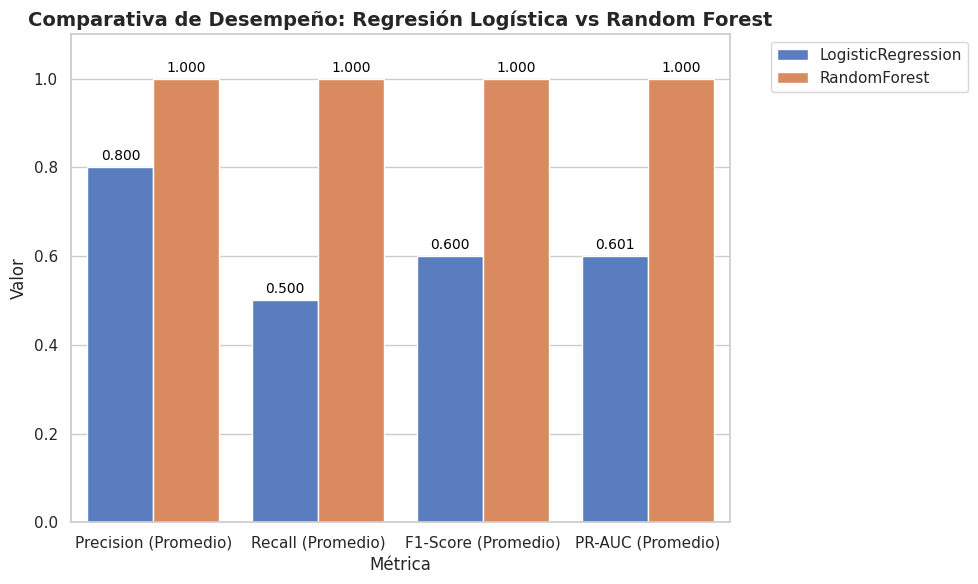

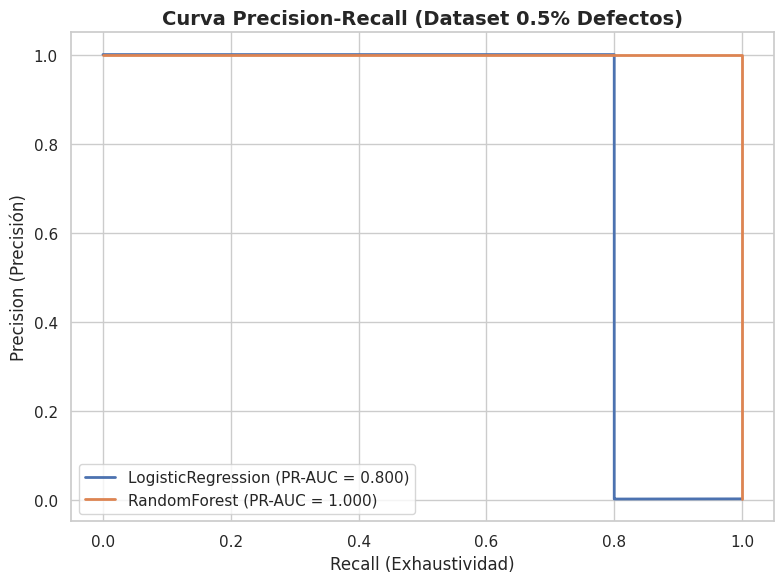

In [15]:
# 6 GRÁFICOS DE DESEMPEÑO (Visualizaciones)

# Gráfico de Barras Comparativo de Métricas Clave
plt.figure(figsize=(10, 6))
df_melted = df_resultados.melt(
    id_vars=["Algoritmo"],
    value_vars=["Precision (Promedio)", "Recall (Promedio)", "F1-Score (Promedio)", "PR-AUC (Promedio)"],
    var_name="Métrica", value_name="Valor"
)

ax = sns.barplot(x="Métrica", y="Valor", hue="Algoritmo", data=df_melted, palette="muted")
plt.title("Comparativa de Desempeño: Regresión Logística vs Random Forest", fontsize=14, fontweight='bold')
plt.ylim(0, 1.1)
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.3f}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, color='black',
                    xytext=(0, 3), textcoords='offset points')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Gráfico de Curva Precision-Recall Promedio (ideal para desbalance de clases)
plt.figure(figsize=(8, 6))
for nombre_modelo, config in modelos_config.items():
    # Entrenar en todo el set para graficar curva representativa
    modelo_plot = GridSearchCV(config["model"], config["params"], scoring='f1', cv=skf).fit(X, y).best_estimator_
    probs = modelo_plot.predict_proba(X)[:, 1]
    precision_vals, recall_vals, _ = precision_recall_curve(y, probs)
    area = auc(recall_vals, precision_vals)

    plt.plot(recall_vals, precision_vals, lw=2, label=f'{nombre_modelo} (PR-AUC = {area:.3f})')

plt.xlabel('Recall (Exhaustividad)', fontsize=12)
plt.ylabel('Precision (Precisión)', fontsize=12)
plt.title('Curva Precision-Recall (Dataset 0.5% Defectos)', fontsize=14, fontweight='bold')
plt.legend(loc='lower left')
plt.grid(True)
plt.tight_layout()
plt.show()